# Phase 2 – Part A: Unsupervised Learning
## Clustering Algorithm 1: K-Means
**Member 1:** Joud Alkahtani


## 1. Clustering Rationale – K-Means

**Goal:** group credit card clients into segments with similar financial behavior, **without using the default label**. The segments can then be used to explain the risk predictions and to support decisions in the executive dashboard.

**Why K-Means:**
- **Dataset size:** the training set has 24,000 clients. K-Means is fast and scales well to this size, while methods that compare every pair of points (such as hierarchical clustering) need much more memory and time.
- **Feature types:** after preprocessing, all features we use are numeric and standardized (mean 0, standard deviation 1), which is what K-Means needs because it groups points by Euclidean distance.
- **Expected cluster shapes:** K-Means assumes roughly spherical (round) clusters of similar spread. This is a simplification for financial data, so we check the cluster quality with several metrics instead of assuming it.
- **Interpretability:** every cluster is described by one center (centroid), so each segment can be explained to a manager as an "average client" of that group.

**Limitations:** the number of clusters *k* must be chosen in advance, and K-Means is sensitive to outliers and to the starting points. We handle this by testing *k* from 2 to 10 and by running each model 10 times with different starting points (`n_init=10`).

In [1]:
# imports and paths
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score

RANDOM_STATE = 42  # same as phase 1
TARGET = "default.payment.next.month"

# works if the notebook is in the repo root or inside Unsupervised_Learning/
ROOT = Path.cwd() if (Path.cwd() / "Dataset").exists() else Path.cwd().parent

RESULTS_DIR = ROOT / "Unsupervised_Learning" / "clustering_results"
PLOTS_DIR = ROOT / "Unsupervised_Learning" / "plots"
MODELS_DIR = ROOT / "Unsupervised_Learning" / "models"
for folder in [RESULTS_DIR, PLOTS_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)

Project root: /content


In [2]:
# load the preprocessed data from phase 1
data = pd.read_csv(ROOT / "Dataset" / "preprocessed_data.csv")

# remove the target (clustering is unsupervised), id and split columns
# also drop the education one-hot columns (0/1 dummies dont work well with distances)
cluster_features = [c for c in data.columns
                    if c not in ["ID", TARGET, "split"] and not c.startswith("EDUCATION_")]

train_mask = data["split"] == "train"
X_all = data[cluster_features]          # all 30,000 clients
X_train_km = X_all[train_mask]          # fit only on the train split (no leakage)

print("Features used:", len(cluster_features))
print(cluster_features)
print("Training rows:", X_train_km.shape[0], "| All rows:", X_all.shape[0])

# scaling check: numeric features were standardized on train in phase 1
scale_check = X_train_km.agg(["mean", "std"]).T.round(2)
display(scale_check.head(8))

assert X_train_km.shape == (24000, 22) and X_all.shape == (30000, 22)
assert np.allclose(scale_check["mean"], 0, atol=0.01) and np.allclose(scale_check["std"], 1, atol=0.01)
print("All features are already standardized (mean 0, std 1).")

Features used: 22
['LIMIT_BAL', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'AGE', 'MONTHS_LATE', 'UTILIZATION', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
Training rows: 24000 | All rows: 30000


,mean,std
LIMIT_BAL,-0.0,1.0
PAY_AMT1,-0.0,1.0
PAY_AMT2,0.0,1.0
PAY_AMT3,-0.0,1.0
PAY_AMT4,0.0,1.0
PAY_AMT5,-0.0,1.0
PAY_AMT6,0.0,1.0
BILL_AMT1,0.0,1.0


All features are already standardized (mean 0, std 1).


## 2. Data Preparation

- **Source:** `Dataset/preprocessed_data.csv`, the output of the preprocessing pipeline in Phase 1.
- **Target removal:** the column `default.payment.next.month` was removed, because clustering is unsupervised and must not see the class label. `ID` and `split` were also removed because they are not client characteristics.
- **EDUCATION columns removed:** the 7 one-hot EDUCATION columns only take values 0 or 1. K-Means measures distance, so these dummy columns would create artificial gaps between clients with different education levels. EDUCATION also had almost no predictive importance in Phase 1 (Section 7 of the supervised notebook). This leaves **22 features**: credit limit, bill amounts, payment amounts, repayment status (PAY_0 to PAY_6), age, and the engineered features MONTHS_LATE and UTILIZATION.
- **Feature scaling:** K-Means is distance-based, so features must be on the same scale; otherwise large monetary values would dominate. The check above confirms that all 22 features were already **standardized** (mean 0, standard deviation 1) by the Phase 1 pipeline, so no extra scaling is needed.
- **Train only:** the model is fitted on the **24,000 training clients** only, using the same split as Phase 1. The 6,000 test clients are then assigned to the nearest cluster. This avoids data leakage if the cluster labels are later used together with the supervised model.

In [3]:
# try k from 2 to 10 and record the 3 metrics
rng = np.random.RandomState(RANDOM_STATE)
sil_idx = rng.choice(len(X_train_km), 5000, replace=False)  # silhouette is slow so use a sample

rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_train_km)
    rows.append({
        "k": k,
        "WCSS": km.inertia_,
        "Silhouette": silhouette_score(X_train_km.iloc[sil_idx], labels[sil_idx]),
        "Davies-Bouldin": davies_bouldin_score(X_train_km, labels),
        "Smallest cluster": np.bincount(labels).min(),
    })

k_search = pd.DataFrame(rows)
k_search.to_csv(RESULTS_DIR / "kmeans_k_selection.csv", index=False)
k_search.round(3)

,k,WCSS,Silhouette,Davies-Bouldin,Smallest cluster
0,2,379462.804,0.331,1.396,6339
1,3,317424.705,0.292,1.407,3596
2,4,281767.309,0.237,1.601,3176
3,5,264001.672,0.238,1.676,2348
4,6,250308.956,0.150,1.821,2136
5,7,242045.957,0.148,1.968,1704
6,8,233114.467,0.148,2.016,1683
7,9,227107.287,0.126,1.959,1668
8,10,221135.644,0.124,1.928,1174


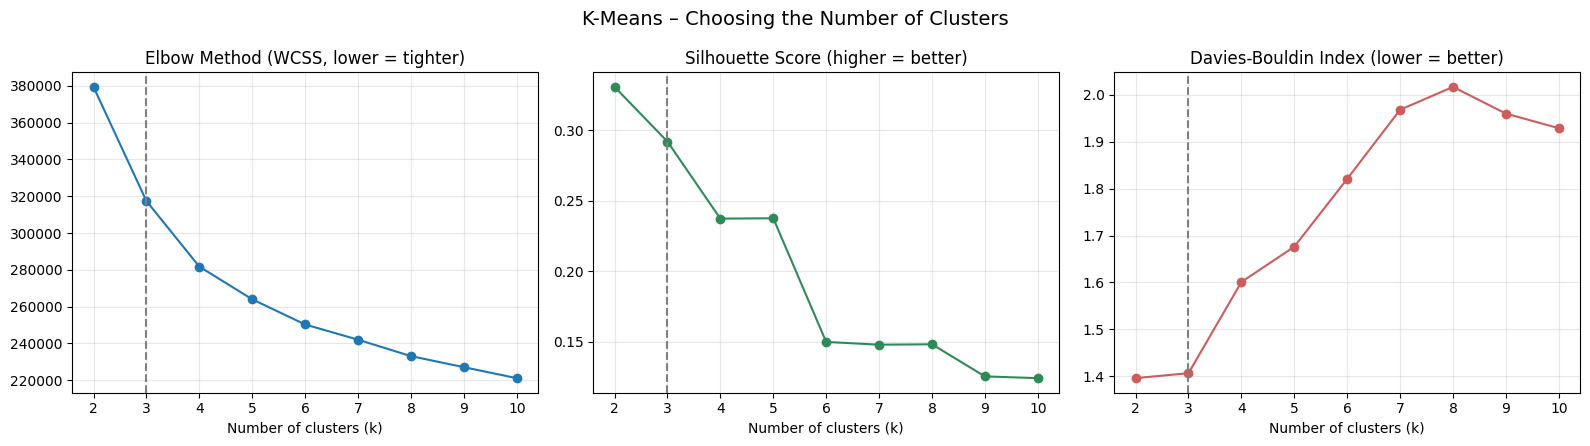

In [4]:
# plot the 3 metrics vs k
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot(k_search["k"], k_search["WCSS"], marker="o")
axes[0].set_title("Elbow Method (WCSS, lower = tighter)")
axes[1].plot(k_search["k"], k_search["Silhouette"], marker="o", color="seagreen")
axes[1].set_title("Silhouette Score (higher = better)")
axes[2].plot(k_search["k"], k_search["Davies-Bouldin"], marker="o", color="indianred")
axes[2].set_title("Davies-Bouldin Index (lower = better)")

for ax in axes:
    ax.set_xlabel("Number of clusters (k)")
    ax.axvline(3, linestyle="--", color="gray")   # chosen k
    ax.grid(alpha=0.3)

plt.suptitle("K-Means – Choosing the Number of Clusters", fontsize=14)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "kmeans_k_selection.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Determining the Optimal Number of Clusters

We trained K-Means for every *k* from 2 to 10 on the training set and compared three metrics:

- **WCSS (Within-Cluster Sum of Squares):** how far points are from their cluster center. It always decreases as *k* grows, so we look for the **elbow**, where adding clusters stops giving a big improvement.
- **Silhouette Score (−1 to 1):** how well each client fits its own cluster compared with the nearest other cluster. Higher is better. It was computed on a random sample of 5,000 training clients, because it compares every pair of points and would be very slow on 24,000 rows.
- **Davies-Bouldin Index:** the average similarity between each cluster and its most similar one. Lower is better.

**Results:**
- The **elbow** is at k = 3: WCSS drops from 379,463 (k=2) to 317,425 (k=3) and 281,767 (k=4), and the decrease becomes much smaller after that.
- **Silhouette** is highest at k=2 (0.331) and k=3 (0.292), then drops sharply to 0.237 at k=4.
- **Davies-Bouldin** is lowest at k=2 (1.396) and k=3 (1.407), and increases after that.

**Chosen k = 3.** k=2 and k=3 have almost the same quality (difference in Silhouette of only 0.039), but k=3 sits at the elbow and gives one more segment, which is more useful for decision-makers. Section 6 shows that the extra cluster separates a clear high-risk group that k=2 does not capture.

In [5]:
# final model with k = 3
K = 3
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE)
kmeans.fit(X_train_km)

# assign every client (train + test) to the nearest center
data["kmeans_cluster"] = kmeans.predict(X_all)
train_labels = data.loc[train_mask, "kmeans_cluster"].values

final_metrics = {
    "k": K,
    "WCSS": kmeans.inertia_,
    "Silhouette (5,000 sample)": silhouette_score(X_train_km.iloc[sil_idx], train_labels[sil_idx]),
    "Davies-Bouldin": davies_bouldin_score(X_train_km, train_labels),
}
print({k: round(float(v), 3) for k, v in final_metrics.items()})

sizes = (data.groupby(["kmeans_cluster", "split"]).size().unstack()
         [["train", "test"]])
sizes["% of train"] = (sizes["train"] / sizes["train"].sum() * 100).round(1)
sizes

{'k': 3.0, 'WCSS': 317424.705, 'Silhouette (5,000 sample)': 0.292, 'Davies-Bouldin': 1.407}


split,train,test,% of train
kmeans_cluster,,,
0,15009,3779,62.5
1,5395,1330,22.5
2,3596,891,15.0


## 4. Final K-Means Model (k = 3)

The final model was trained on the 24,000 training clients and then used to assign all 30,000 clients to a cluster.

**Quality:** Silhouette = 0.292 and Davies-Bouldin = 1.407. A Silhouette around 0.3 means the clusters are reasonably separated but overlap at their borders, which is expected for credit card clients, whose behavior changes gradually rather than falling into perfectly separate groups.

**Cluster sizes:** the clusters contain 62.5%, 22.5% and 15.0% of the training clients. No cluster is tiny, so every segment is large enough to be meaningful for the bank. The test clients are distributed in similar proportions, which shows that the clusters generalize to unseen clients.

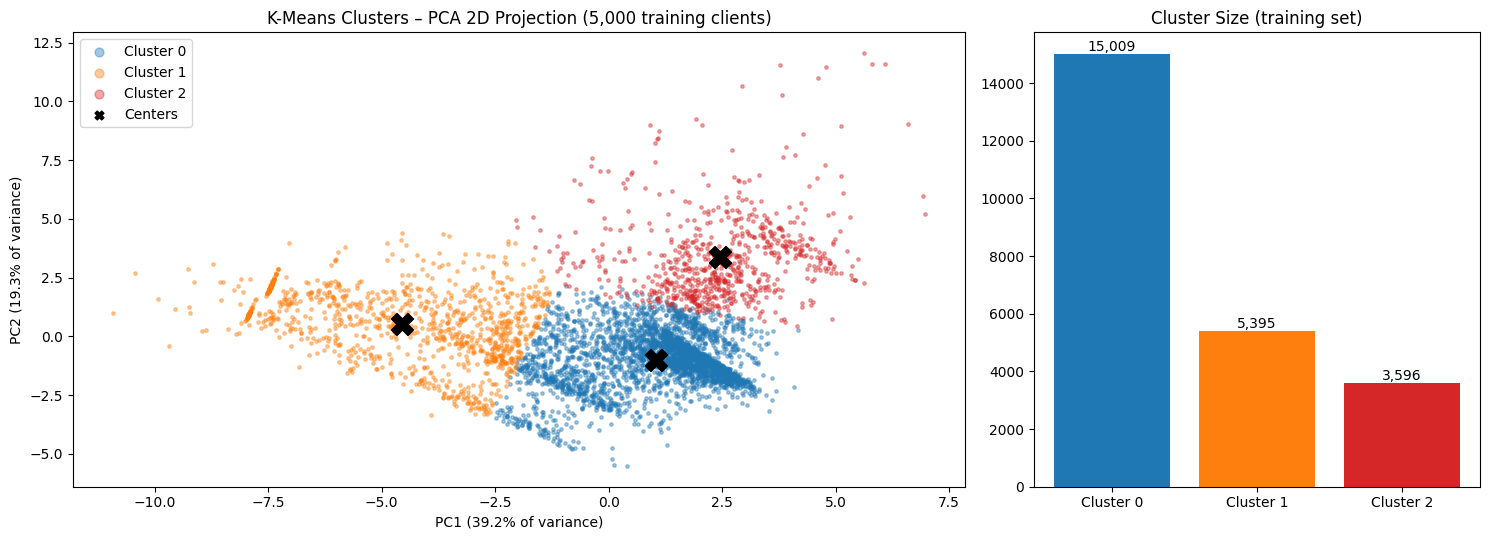

PC1 + PC2 explain 58.5% of the variance


In [6]:
# 2d pca projection to see the clusters
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_train_km)
points = pca.transform(X_train_km.iloc[sil_idx])        # same 5,000 sample
centers = pca.transform(pd.DataFrame(kmeans.cluster_centers_, columns=cluster_features))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [2, 1]})

colors = ["tab:blue", "tab:orange", "tab:red"]
for c in range(K):
    m = train_labels[sil_idx] == c
    axes[0].scatter(points[m, 0], points[m, 1], s=6, alpha=0.4, color=colors[c], label=f"Cluster {c}")
axes[0].scatter(centers[:, 0], centers[:, 1], s=250, marker="X", color="black", label="Centers")
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% of variance)")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% of variance)")
axes[0].set_title("K-Means Clusters – PCA 2D Projection (5,000 training clients)")
leg = axes[0].legend()
for h in leg.legend_handles:
    h.set_sizes([40])   # keep legend dots small

counts = np.bincount(train_labels)
axes[1].bar([f"Cluster {c}" for c in range(K)], counts, color=colors)
for i, v in enumerate(counts):
    axes[1].text(i, v, f"{v:,}", ha="center", va="bottom")
axes[1].set_title("Cluster Size (training set)")

plt.tight_layout()
plt.savefig(PLOTS_DIR / "kmeans_pca_and_sizes.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"PC1 + PC2 explain {pca.explained_variance_ratio_[:2].sum()*100:.1f}% of the variance")

**Interpretation:**

- **PCA projection (left):** the 22 features were reduced to 2 dimensions only to draw the clusters. These two components explain 58.5% of the variance, so the picture is a simplified view and some overlap is expected. Still, the three clusters occupy different regions, and the centers (black X) are clearly apart.
- **Cluster sizes (right):** Cluster 0 is the largest group (15,009 clients), Cluster 1 has 5,395 clients, and Cluster 2 has 3,596 clients.

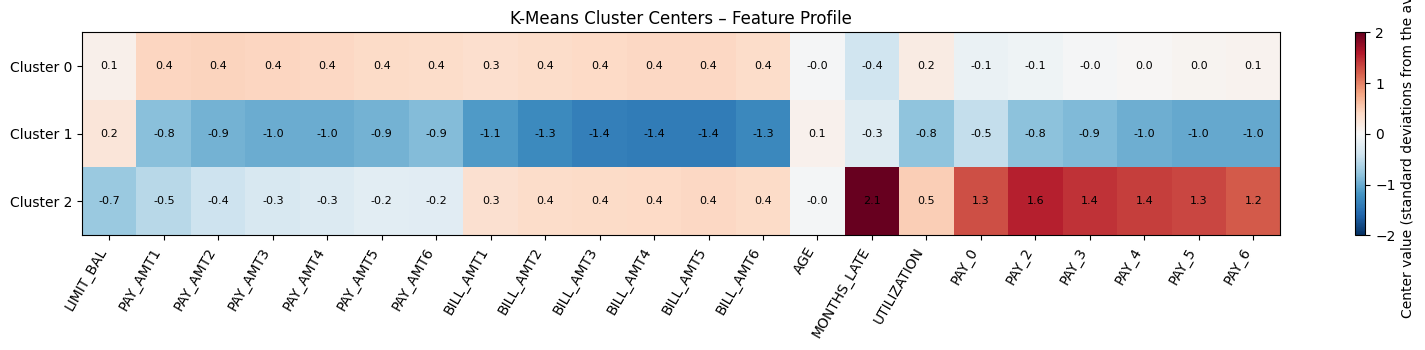

In [7]:
# feature profile per cluster = center values (in std units)
center_df = pd.DataFrame(kmeans.cluster_centers_, columns=cluster_features,
                         index=[f"Cluster {c}" for c in range(K)])
center_df.T.round(2).to_csv(RESULTS_DIR / "kmeans_cluster_centers.csv")

fig, ax = plt.subplots(figsize=(16, 3.6))
im = ax.imshow(center_df.values, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(cluster_features)))
ax.set_xticklabels(cluster_features, rotation=60, ha="right")
ax.set_yticks(range(K))
ax.set_yticklabels(center_df.index)
for i in range(K):
    for j in range(len(cluster_features)):
        ax.text(j, i, f"{center_df.values[i, j]:.1f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, label="Center value (standard deviations from the average)")
ax.set_title("K-Means Cluster Centers – Feature Profile")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "kmeans_cluster_centers.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Feature Profile per Cluster

The heatmap shows each cluster's center. Because the features are standardized, 0 means "average client", red means above average and blue means below average.

- **Cluster 0 – Active, on-time clients:** above-average bill amounts (+0.3 to +0.4) and payment amounts (about +0.4), with fewer late months than average (MONTHS_LATE −0.4) and repayment status close to normal (PAY_0 to PAY_6 between −0.1 and +0.1). These clients use their cards and pay regularly.
- **Cluster 1 – Low-activity clients:** clearly below-average bill amounts (−1.1 to −1.4), payment amounts (−0.8 to −1.0) and utilization (−0.8), with repayment status well below average (around −1.0, meaning no use or paid in full). These clients barely use their cards.
- **Cluster 2 – Late-paying, high-risk clients:** very high MONTHS_LATE (+2.1) and repayment status codes (PAY_0 to PAY_6 between +1.2 and +1.6), a lower credit limit (−0.7), above-average utilization (+0.5), and below-average payments (−0.2 to −0.5) despite above-average bills. These clients carry debt but repeatedly pay late.

The features that separate the clusters the most are the **repayment status features (PAY_0 to PAY_6, MONTHS_LATE)** and the **bill amounts**, which matches the most important features of the Random Forest model in Phase 1.

In [8]:
# quick check: default rate per cluster (label used only after clustering, never in training)
check = {}
for k in [2, 3]:
    km_k = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_train_km)
    rates = (pd.Series(data.loc[train_mask, TARGET].values)
             .groupby(km_k.labels_).mean() * 100)
    check[f"k = {k}"] = rates.round(1)

default_check = pd.DataFrame(check)
default_check.index = [f"Cluster {c}" for c in default_check.index]
default_check.index.name = "Default rate (%) in train"
default_check = default_check.fillna("-")   # k=2 has no cluster 2
default_check

,k = 2,k = 3
Default rate (%) in train,,
Cluster 0,22.7,13.8
Cluster 1,20.6,21.5
Cluster 2,-,57.6


## 6. Validation of the Chosen k with the Default Label

The default label was **not** used to build the clusters. We only use it here, after clustering, to check whether the segments are meaningful for the bank (overall default rate in the training set: 22.1%).

- **k = 2:** the two clusters have similar default rates (22.7% and 20.6%). They mainly separate active card users from inactive ones, which does not help the bank distinguish risk.
- **k = 3:** Cluster 2 has a default rate of 57.6%, about 2.6 times the overall rate, while Cluster 0 has only 13.8%. The third cluster isolates a **high-risk segment** that k=2 mixes with the other clients.

This confirms the choice of **k = 3**: it has almost the same Silhouette and Davies-Bouldin scores as k=2, but its segments are much more useful for decision-making.

In [9]:
# save everything for member 2, member 3 and the dashboard
data[["ID", "split", "kmeans_cluster"]].to_csv(RESULTS_DIR / "kmeans_labels.csv", index=False)

pd.DataFrame([final_metrics]).to_csv(RESULTS_DIR / "kmeans_final_metrics.csv", index=False)

joblib.dump(kmeans, MODELS_DIR / "kmeans_model.joblib")
with open(RESULTS_DIR / "kmeans_features.json", "w") as f:
    json.dump(cluster_features, f, indent=2)   # needed to use the model on new clients

print("Results:", sorted(p.name for p in RESULTS_DIR.glob("kmeans_*")))
print("Plots:  ", sorted(p.name for p in PLOTS_DIR.glob("kmeans_*")))
print("Model:  ", sorted(p.name for p in MODELS_DIR.glob("kmeans_*")))

Results: ['kmeans_cluster_centers.csv', 'kmeans_features.json', 'kmeans_final_metrics.csv', 'kmeans_k_selection.csv', 'kmeans_labels.csv']
Plots:   ['kmeans_cluster_centers.png', 'kmeans_k_selection.png', 'kmeans_pca_and_sizes.png']
Model:   ['kmeans_model.joblib']


## 7. K-Means Summary

| Item | Value |
|---|---|
| Features used | 22 standardized features (target, ID, split and EDUCATION removed) |
| Fitted on | 24,000 training clients (all 30,000 clients assigned) |
| Chosen k | 3 (elbow + Silhouette + Davies-Bouldin + business meaning) |
| Silhouette | 0.292 |
| Davies-Bouldin | 1.407 |
| Cluster sizes (train) | 15,009 / 5,395 / 3,596 |

**Outputs for the next steps:**
- `clustering_results/kmeans_labels.csv`: the K-Means cluster of every client (`ID`, `split`, `kmeans_cluster`), used for the comparison with the second algorithm and for the cluster profiles.
- `clustering_results/kmeans_k_selection.csv`, `kmeans_final_metrics.csv`, `kmeans_cluster_centers.csv`: all evaluation metrics as CSV files.
- `plots/`: all K-Means figures as PNG files.
- `models/kmeans_model.joblib` + `kmeans_features.json`: the trained model and its feature list, so the dashboard can assign a new client to a segment.